# Sleep Quality



# Fuzzy Inference System (FIS) Design, Implementation, and Evaluation

## 1. Overview & Objectives

This notebook implements a Mamdani Fuzzy Inference System (FIS) to predict **sleep efficiency** based on three physiological antecedents: **HRV (Heart Rate Variability)**, **Day Strain**, and **Wake-ups**. The objective is to map human physiological indicators and nighttime stability into a continuous sleep performance score ranging from $0$ to $100\%$.

---

## 2. Initial Design Choices & Justification (First Iteration)

In this initial implementation, the universes of discourse, membership functions, and rule base were designed based on heuristic physiological reasoning and standard ranges:

* **Inputs (Antecedents):**
* **`hrv` (Range: $20$ to $150$ ms):** Divided into `low`, `medium`, and `high` using triangular membership functions. *Justification:* Captures an individual's autonomic nervous system recovery capacity.
* **`day_strain` (Range: $0$ to $21$):** Divided into `low`, `medium`, and `high`. *Justification:* Reflects daily cardiovascular and physical load (modeled after standard fitness tracking metrics like Whoop).
* **`wake_ups` (Range: $0$ to $10$):** Divided into `few`, `medium`, and `many`. *Justification:* Quantifies sleep fragmentation.


* **Output (Consequent):**
* **`sleep_efficiency` (Range: $0$ to $100\%$):** Divided into `poor`, `average`, and `excellent`.


* **Rule Base:**
* A full combinatorial rule base of $27$ rules ($3 \times 3 \times 3$) was constructed, translating common-sense biological scenarios (e.g., *Golden Rule of Recovery*: High HRV + Moderate Strain + Few Wake-ups $\rightarrow$ Excellent Sleep Efficiency).





---

## 3. Evaluation & Critical Findings

When running inference on the preprocessed dataset and visualizing the results, the initial configuration yielded suboptimal quantitative performance:

* **Quantitative Metrics:** The model produced a high error rate ($\text{MAE} \approx 15$, $\text{RMSE} \approx 17.7$) and a negative $R^2$ score, indicating that the system's predictions did not align well with the ground truth variance.
* **Root Cause Analysis:**
1. *Data Distribution Mismatch:* Real-world sleep efficiency values in the cleaned dataset do not span uniformly from $0$ to $100\%$; they are densely concentrated in higher brackets (typically $70\%$ to $95\%$).
2. *Granularity and Shape:* The membership functions for `wake_ups` and the output categories were too broad or misaligned with the actual frequency of the data, leading to dead zones where rules failed to fire properly (resulting in `NaN` outputs for a subset of samples).



---

## 4. Conclusion & Next Steps (Branching Strategy)

The initial setup proved that a purely heuristic configuration fails to capture the nuances of the dataset.

* **Decision:** Rather than cluttering the main experimental pipeline, this current iteration is preserved as a baseline.
* To fix these issues, a new branch will be created where I will:
    * Refine the universes of discourse and trim/trapezoidal boundaries based on statistical percentiles of the dataset rather than arbitrary assumptions.
    * Recalibrate the linguistic terms of the output to match the true data distribution.
    * Tune or filter the rule base to maximize firing coverage and minimize inference gaps.

## Imports

In [12]:
import sys
import os
import pandas as pd
import numpy as np
from skfuzzy.control import Rule

sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from preprocessor import clean_missing_values
from mamdani_engine import GenericMamdaniEngine
from evaluation import (
    evaluate_regression, 
    plot_regression_results, 
    plot_membership_functions, 
    plot_control_surface
)

## Data Preprocessing

In [13]:
# File paths
raw_path = '../data/raw/whoop_fitness_dataset_100k.csv'
processed_path = '../data/processed/whoop_clean.csv'

# Data Loading & Preprocessing using the general preprocessor
if not os.path.exists(processed_path):
    print("Loading raw data and applying general preprocessing...")
    df_raw = pd.read_csv(raw_path)
    selected_cols = ['hrv', 'day_strain', 'wake_ups', 'sleep_efficiency']
    df_subset = df_raw[selected_cols].copy()
    
    df_clean = clean_missing_values(df_subset, subset_columns=selected_cols)
    
    os.makedirs(os.path.dirname(processed_path), exist_ok=True)
    df_clean.to_csv(processed_path, index=False)
    print(f"Clean dataset saved to: {processed_path}")
else:
    print("Loading preprocessed dataset...")
    df_clean = pd.read_csv(processed_path)

print(f"Dataset shape: {df_clean.shape}")
df_clean.head()

Loading preprocessed dataset...
Dataset shape: (100000, 4)


,hrv,day_strain,wake_ups,sleep_efficiency
0,118.3,7.33,1,72.3
1,105.7,10.38,1,78.3
2,95.3,7.16,0,78.8
3,76.2,16.47,0,80.3
4,94.4,16.67,0,73.0


## Mamdani FIS Configuration & Membership Functions

--- Generare Grafice Funcții de Apartenență (Antecedente) ---


c:\Users\david\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


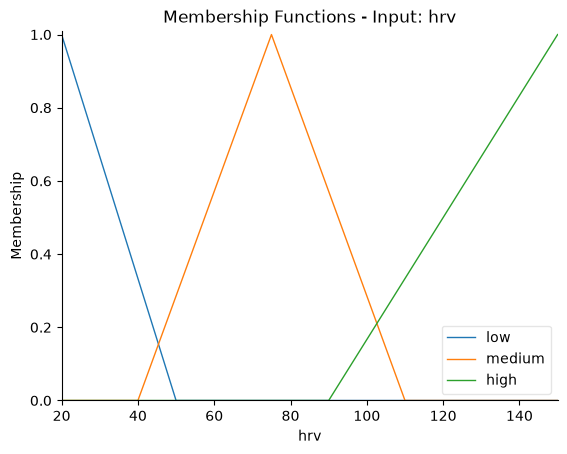

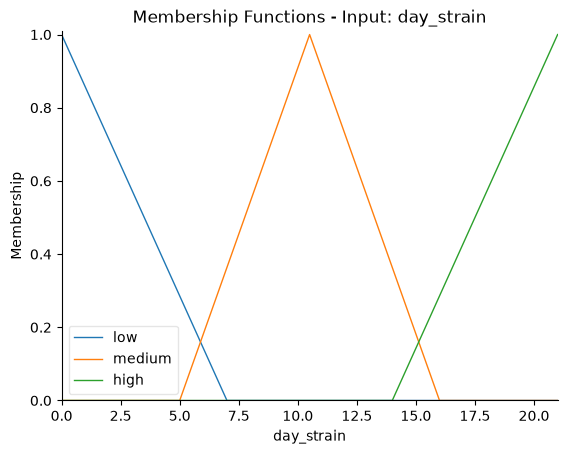

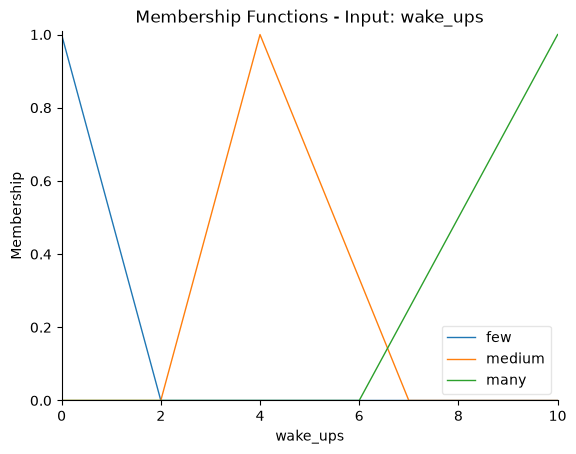

--- Generare Grafice Funcții de Apartenență (Consecvent) ---


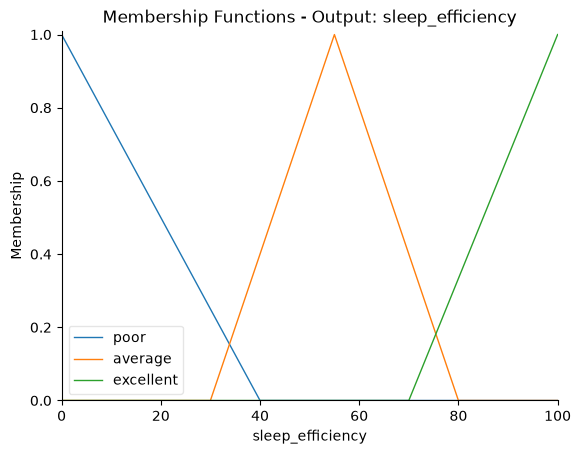

In [14]:
# Instantiate Mamdani Engine
fis = GenericMamdaniEngine()

# Define Antecedents (Inputs)
fis.add_antecedent('hrv', np.arange(20, 151, 1), {
    'low': [20, 20, 50],
    'medium': [40, 75, 110],
    'high': [90, 150, 150]
})

fis.add_antecedent('day_strain', np.arange(0, 21.1, 0.5), {
    'low': [0, 0, 7],
    'medium': [5, 10.5, 16],
    'high': [14, 21, 21]
})

fis.add_antecedent('wake_ups', np.arange(0, 11, 1), {
    'few': [0, 0, 2],
    'medium': [2, 4, 7],
    'many': [6, 10, 10]
})

# Define Consequent (Output)
fis.add_consequent('sleep_efficiency', np.arange(0, 101, 1), {
    'poor': [0, 0, 40],
    'average': [30, 55, 80],
    'excellent': [70, 100, 100]
})

# Visualize Membership Functions (as requested)
plot_membership_functions(fis)

## IF-THEN Rules Definition

In [15]:
# Definition of all 27 IF-THEN Rules (Complete combinatorial rule base)
ant = fis.antecedents
cons = fis.consequents

rules = [
    # HRV = Low
    Rule(ant['hrv']['low'] & ant['day_strain']['low'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
    Rule(ant['hrv']['low'] & ant['day_strain']['low'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['low'] & ant['day_strain']['low'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['low'] & ant['day_strain']['medium'] & ant['wake_ups']['few'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['low'] & ant['day_strain']['medium'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['low'] & ant['day_strain']['medium'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['low'] & ant['day_strain']['high'] & ant['wake_ups']['few'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['low'] & ant['day_strain']['high'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['low'] & ant['day_strain']['high'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    
    # HRV = Medium
    Rule(ant['hrv']['medium'] & ant['day_strain']['low'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
    Rule(ant['hrv']['medium'] & ant['day_strain']['low'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
    Rule(ant['hrv']['medium'] & ant['day_strain']['low'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['medium'] & ant['day_strain']['medium'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
    Rule(ant['hrv']['medium'] & ant['day_strain']['medium'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
    Rule(ant['hrv']['medium'] & ant['day_strain']['medium'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['medium'] & ant['day_strain']['high'] & ant['wake_ups']['few'], cons['sleep_efficiency']['average']),
    Rule(ant['hrv']['medium'] & ant['day_strain']['high'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['medium'] & ant['day_strain']['high'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    
    # HRV = High
    Rule(ant['hrv']['high'] & ant['day_strain']['low'] & ant['wake_ups']['few'], cons['sleep_efficiency']['excellent']),
    Rule(ant['hrv']['high'] & ant['day_strain']['low'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
    Rule(ant['hrv']['high'] & ant['day_strain']['low'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['high'] & ant['day_strain']['medium'] & ant['wake_ups']['few'], cons['sleep_efficiency']['excellent']),
    Rule(ant['hrv']['high'] & ant['day_strain']['medium'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
    Rule(ant['hrv']['high'] & ant['day_strain']['medium'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor']),
    Rule(ant['hrv']['high'] & ant['day_strain']['high'] & ant['wake_ups']['few'], cons['sleep_efficiency']['excellent']),
    Rule(ant['hrv']['high'] & ant['day_strain']['high'] & ant['wake_ups']['medium'], cons['sleep_efficiency']['average']),
    Rule(ant['hrv']['high'] & ant['day_strain']['high'] & ant['wake_ups']['many'], cons['sleep_efficiency']['poor'])
]

# Build control system with all 27 rules
fis.build_system(rules)
print(f"Mamdani control system successfully built with {len(rules)} rules!")

Mamdani control system successfully built with 27 rules!


## Running Inference on Dataset

In [16]:
# Run Inference on a sample of the clean dataset
df_sample = df_clean.head(500).copy()
input_features = ['hrv', 'day_strain', 'wake_ups']

print("Running fuzzy inference on dataset...")
y_pred = fis.predict_dataset(df_sample, input_features)
y_true = df_sample['sleep_efficiency'].values

# Filter out potential NaNs
valid_idx = ~np.isnan(y_pred)
y_true_clean = y_true[valid_idx]
y_pred_clean = y_pred[valid_idx]

print(f"Inference complete for {len(y_pred_clean)} valid samples.")

Running fuzzy inference on dataset...
Inference complete for 450 valid samples.


## Evaluation and Visualization

--- Quantitative Error Metrics Table ---


,Metric,Value
0,MAE (Mean Absolute Error),14.990157
1,MSE (Mean Squared Error),312.787674
2,RMSE (Root Mean Squared Error),17.685804
3,R2 Score,-2.037724


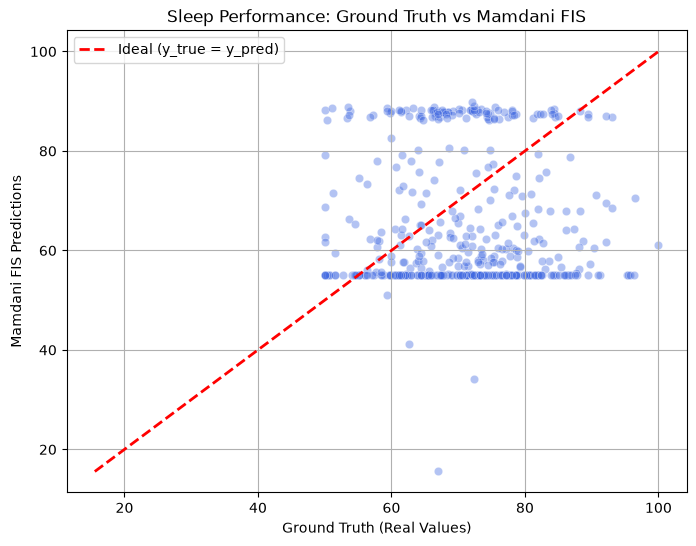

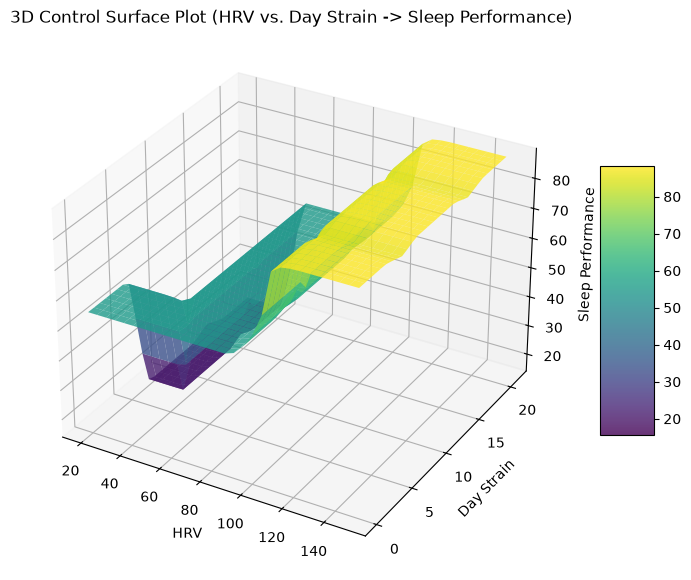

In [17]:
# 1. Quantitative Error Table
metrics_df = evaluate_regression(y_true_clean, y_pred_clean)
print("--- Quantitative Error Metrics Table ---")
display(metrics_df)

# 2. Regression Scatter Plot (Real vs Predicted)
plot_regression_results(y_true_clean, y_pred_clean, title='Sleep Performance: Ground Truth vs Mamdani FIS')

# 3. 3D Control Surface Plot
plot_control_surface(fis.simulation, 'hrv', 'day_strain', 'sleep_efficiency')